In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix
import itertools

In [2]:
!nvidia-smi

Mon Oct 12 23:00:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   54C    P8              6W /   60W |     149MiB /   6144MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Dataset Parsing & Formulation (Variable-Length Sequences)

Each blank-line-separated block in the original UCI files is one utterance, represented by a variable-length sequence of 13 MFCC features per frame.

**Important label correction:** the original files are ordered by digit. The training file contains 660 consecutive utterances for each digit (0 through 9); the test file contains 220 consecutive utterances for each digit. Therefore, the label is `utterance_index // utterances_per_digit`, not `(index // 10) % 10`.

In [4]:
class SpokenArabicDigitDataset(Dataset):
    def __init__(self, file_path, utterances_per_digit):
        self.sequences = []
        self.labels = []
        self.utterances_per_digit = utterances_per_digit

        # Every blank-line-separated block is one utterance.
        with open(file_path, "r", encoding="utf-8") as f:
            current_seq = []

            for line_number, line in enumerate(f, start=1):
                line = line.strip()

                if not line:
                    if current_seq:
                        self.sequences.append(
                            torch.tensor(current_seq, dtype=torch.float32)
                        )
                        current_seq = []
                    continue

                try:
                    features = [float(value) for value in line.split()]
                except ValueError as exc:
                    raise ValueError(
                        f"Could not parse numeric features at line {line_number} "
                        f"in {file_path}: {line!r}"
                    ) from exc

                if len(features) != 13:
                    raise ValueError(
                        f"Expected 13 MFCC values at line {line_number}, "
                        f"found {len(features)}."
                    )

                current_seq.append(features)

            # Include the last utterance if there is no trailing blank line.
            if current_seq:
                self.sequences.append(
                    torch.tensor(current_seq, dtype=torch.float32)
                )

        expected_count = utterances_per_digit * 10
        if len(self.sequences) != expected_count:
            raise ValueError(
                f"{file_path}: expected {expected_count} utterances "
                f"({utterances_per_digit} per digit), but parsed "
                f"{len(self.sequences)}. Check the source file and blank-line "
                f"separators."
            )

        # Official UCI files are ordered by digit: all digit-0 utterances,
        # followed by digit 1, ..., through digit 9.
        self.labels = [
            idx // utterances_per_digit for idx in range(len(self.sequences))
        ]

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], torch.tensor(
            self.labels[idx], dtype=torch.long
        )

## Data Collation (Padding) & Loaders

The RNN/LSTM/GRU models receive batches shaped `(batch, max_sequence_length, 13)`. Sequences are sorted by length before packing so `pack_padded_sequence` can use `enforce_sorted=True`.

In [5]:
def collate_fn(batch):
    # pack_padded_sequence with enforce_sorted=True requires descending lengths.
    batch = sorted(batch, key=lambda item: item[0].shape[0], reverse=True)
    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [seq.shape[0] for seq in sequences], dtype=torch.long
    )
    padded_seqs = pad_sequence(sequences, batch_first=True)
    labels = torch.stack(labels)

    return padded_seqs, labels, lengths


# Keep these files in the notebook's current working directory.
train_dataset = SpokenArabicDigitDataset(
    "Train_Arabic_Digit.txt", utterances_per_digit=660
)
test_dataset = SpokenArabicDigitDataset(
    "Test_Arabic_Digit.txt", utterances_per_digit=220
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, collate_fn=collate_fn
)
test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False, collate_fn=collate_fn
)

print(f"Loaded train utterances: {len(train_dataset)}")
print(f"Loaded test utterances:  {len(test_dataset)}")
print("Training examples per digit:",
      {digit: train_dataset.labels.count(digit) for digit in range(10)})
print("Test examples per digit:",
      {digit: test_dataset.labels.count(digit) for digit in range(10)})

assert len(train_dataset) == 6600
assert len(test_dataset) == 2200
assert set(train_dataset.labels) == set(range(10))
assert set(test_dataset.labels) == set(range(10))

Loaded train utterances: 6600
Loaded test utterances:  2200
Training examples per digit: {0: 660, 1: 660, 2: 660, 3: 660, 4: 660, 5: 660, 6: 660, 7: 660, 8: 660, 9: 660}
Test examples per digit: {0: 220, 1: 220, 2: 220, 3: 220, 4: 220, 5: 220, 6: 220, 7: 220, 8: 220, 9: 220}


## Unified Model Architecture (with Sequence Packing)

In [6]:
class SpokenDigitClassifier(nn.Module):
    def __init__(
        self, input_size=13, hidden_size=64, num_layers=2,
        num_classes=10, rnn_type="LSTM"
    ):
        super().__init__()
        self.rnn_type = rnn_type.upper()

        if self.rnn_type == "RNN":
            self.rnn = nn.RNN(
                input_size, hidden_size, num_layers, batch_first=True
            )
        elif self.rnn_type == "LSTM":
            self.rnn = nn.LSTM(
                input_size, hidden_size, num_layers, batch_first=True
            )
        elif self.rnn_type == "GRU":
            self.rnn = nn.GRU(
                input_size, hidden_size, num_layers, batch_first=True
            )
        else:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x, lengths):
        packed_input = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=True
        )

        if self.rnn_type == "LSTM":
            _, (hn, _) = self.rnn(packed_input)
        else:
            _, hn = self.rnn(packed_input)

        # hn[-1] is the final hidden state of the top recurrent layer.
        return self.fc(hn[-1])

## Training & Evaluation Functions

Training now has a maximum epoch limit and patience-based early stopping, so it cannot run indefinitely or stop merely because two consecutive losses happen to be close. The stopping criterion uses training loss; the test set is reserved for evaluation.

In [7]:
def train_and_evaluate_audio(
    model,
    train_loader,
    learning_rate=0.001,
    max_epochs=100,
    patience=8,
    min_delta=1e-4
):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    loss_history = []
    best_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(max_epochs):
        model.train()
        running_loss = 0.0

        for sequences, labels, lengths in train_loader:
            sequences = sequences.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(sequences, lengths)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * sequences.size(0)

        avg_train_loss = running_loss / len(train_loader.dataset)
        loss_history.append(avg_train_loss)

        if avg_train_loss < best_loss - min_delta:
            best_loss = avg_train_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"Epoch {epoch + 1}/{max_epochs} | "
                f"Train loss: {avg_train_loss:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

    return model, loss_history, len(loss_history)


def get_audio_accuracy(model, data_loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for sequences, labels, lengths in data_loader:
            sequences = sequences.to(device)
            labels = labels.to(device)
            outputs = model(sequences, lengths)
            predicted = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return 100.0 * correct / total if total else 0.0

## Hyperparameter Tuning Loop

The experiment compares 18 configurations: RNN, LSTM, and GRU; hidden sizes 32, 64, and 128; and 1 or 2 recurrent layers. A fixed random seed makes the run more reproducible.

In [8]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

hidden_sizes = [32, 64, 128]
num_layers_list = [1, 2]
rnn_types = ["RNN", "LSTM", "GRU"]

tuning_results_audio = []
loss_histories_audio = {}
trained_models_dict_audio = {}

for rnn_type, hidden_size, num_layers in itertools.product(
    rnn_types, hidden_sizes, num_layers_list
):
    config_name = f"{rnn_type}_N{hidden_size}_L{num_layers}"
    print(f"\nTraining {config_name}...")

    model = SpokenDigitClassifier(
        hidden_size=hidden_size,
        num_layers=num_layers,
        rnn_type=rnn_type
    )

    trained_model, loss_history, epochs_run = train_and_evaluate_audio(
        model, train_loader, learning_rate=0.001,
        max_epochs=100, patience=8
    )

    train_acc = get_audio_accuracy(trained_model, train_loader)
    test_acc = get_audio_accuracy(trained_model, test_loader)

    loss_histories_audio[config_name] = loss_history
    trained_models_dict_audio[config_name] = trained_model

    tuning_results_audio.append({
        "Model": rnn_type,
        "Neurons": hidden_size,
        "Layers": num_layers,
        "Epochs": epochs_run,
        "Train Acc (%)": round(train_acc, 2),
        "Test Acc (%)": round(test_acc, 2)
    })

    print(
        f"{config_name}: train accuracy={train_acc:.2f}%, "
        f"test accuracy={test_acc:.2f}%"
    )


Training RNN_N32_L1...
Epoch 1/100 | Train loss: 2.0759
Epoch 10/100 | Train loss: 1.2057
Epoch 20/100 | Train loss: 1.1084
Early stopping at epoch 24
RNN_N32_L1: train accuracy=66.35%, test accuracy=62.27%

Training RNN_N32_L2...
Epoch 1/100 | Train loss: 1.9187
Epoch 10/100 | Train loss: 0.9305
Epoch 20/100 | Train loss: 0.6307
Epoch 30/100 | Train loss: 0.5004
Epoch 40/100 | Train loss: 0.3445
Epoch 50/100 | Train loss: 1.4308
Early stopping at epoch 57
RNN_N32_L2: train accuracy=86.82%, test accuracy=79.32%

Training RNN_N64_L1...
Epoch 1/100 | Train loss: 1.8346
Epoch 10/100 | Train loss: 0.7265
Epoch 20/100 | Train loss: 0.5514
Epoch 30/100 | Train loss: 1.0475
Early stopping at epoch 30
RNN_N64_L1: train accuracy=65.42%, test accuracy=56.14%

Training RNN_N64_L2...
Epoch 1/100 | Train loss: 1.7126
Epoch 10/100 | Train loss: 1.8596
Early stopping at epoch 16
RNN_N64_L2: train accuracy=47.06%, test accuracy=46.18%

Training RNN_N128_L1...
Epoch 1/100 | Train loss: 1.5583
Epoch 10

## Complete Summary Table of All Models

In [9]:
from IPython.display import display

results_audio_df = pd.DataFrame(tuning_results_audio)
results_audio_df.sort_values(by=['Test Acc (%)'], ascending=False, inplace=True)

print("Complete Summary Table (Audio MFCC Configurations):")
display(results_audio_df)

Complete Summary Table (Audio MFCC Configurations):


,Model,Neurons,Layers,Epochs,Train Acc (%),Test Acc (%)
16,GRU,128,1,46,100.00,97.73
17,GRU,128,2,37,100.00,97.73
10,LSTM,128,1,48,100.00,97.68
7,LSTM,32,2,48,99.97,97.59
11,LSTM,128,2,38,100.00,97.59
8,LSTM,64,1,71,100.00,97.23
15,GRU,64,2,54,100.00,97.09
9,LSTM,64,2,49,100.00,96.95
14,GRU,64,1,66,100.00,96.82
12,GRU,32,1,81,100.00,95.82


## Best Model Summary Table

In [10]:
best_audio_summary = results_audio_df.head(1).copy()
print("Best Audio Model Summary Table:")
display(best_audio_summary)

Best Audio Model Summary Table:


,Model,Neurons,Layers,Epochs,Train Acc (%),Test Acc (%)
16,GRU,128,1,46,100.0,97.73


## Plotting Curves

### Vanilla RNN Learning Curves

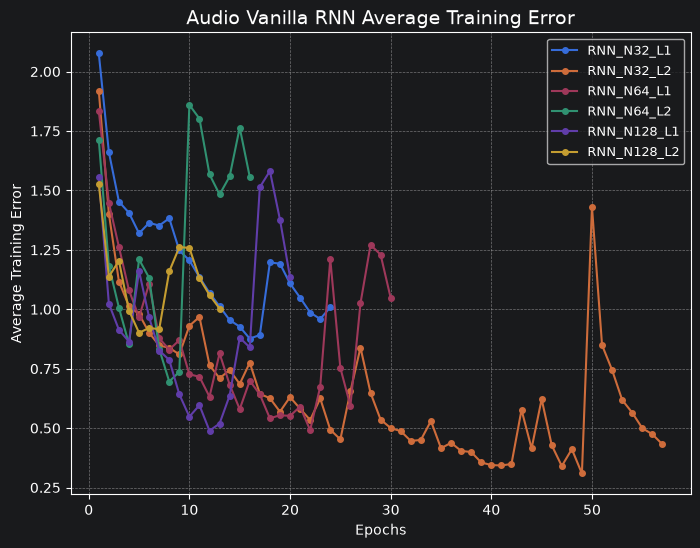

In [11]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories_audio.items():
    if config.startswith('RNN'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Audio Vanilla RNN Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

### LSTM Learning Curves

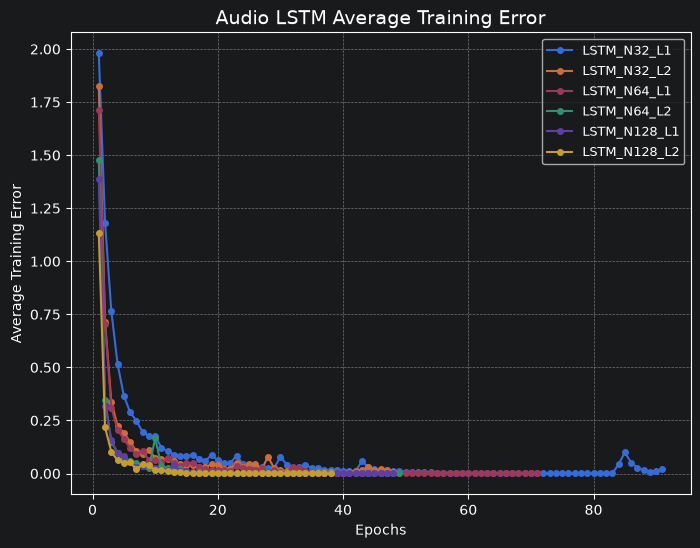

In [12]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories_audio.items():
    if config.startswith('LSTM'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Audio LSTM Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

### GRU Learning Curves

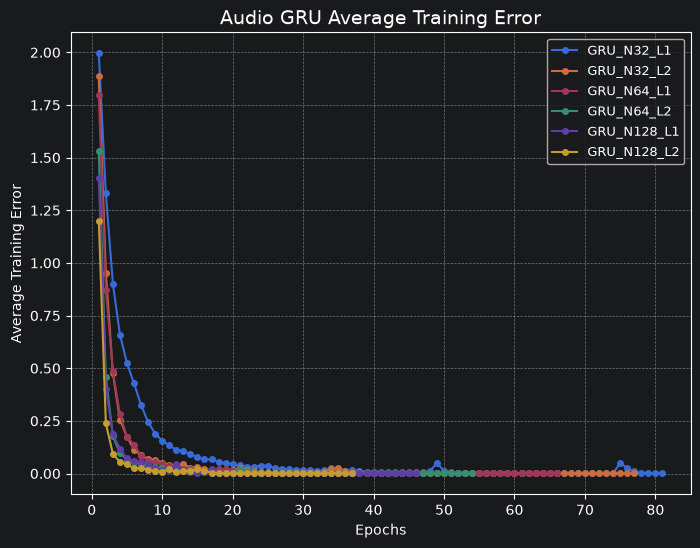

In [13]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories_audio.items():
    if config.startswith('GRU'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Audio GRU Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

## Best Model Complete Confusion Matrix

Best Audio Configuration: GRU_N128_L1


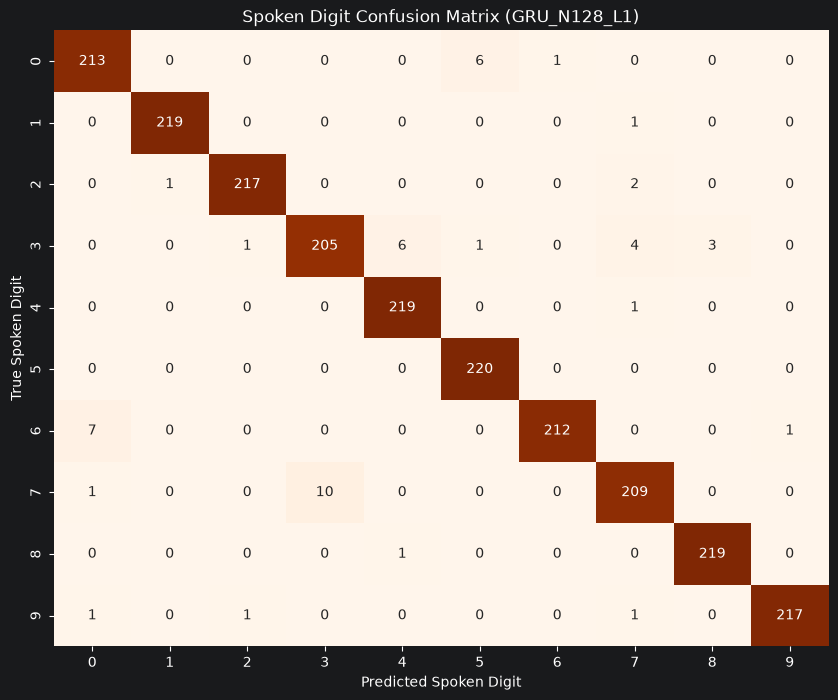

In [14]:
best_config = results_audio_df.iloc[0]
best_model_name = f"{best_config['Model']}_N{best_config['Neurons']}_L{best_config['Layers']}"
best_model = trained_models_dict_audio[best_model_name]

print(f"Best Audio Configuration: {best_model_name}")

def get_audio_preds(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for sequences, labels, lengths in loader:
            sequences = sequences.to(device)
            outputs = model(sequences, lengths)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return all_labels, all_preds

test_y, test_pred = get_audio_preds(best_model, test_loader)
cm = confusion_matrix(test_y, test_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.xlabel('Predicted Spoken Digit')
plt.ylabel('True Spoken Digit')
plt.title(f'Spoken Digit Confusion Matrix ({best_model_name})')
plt.show()

## Qualitative Visualizations (MFCC Heatmaps)

These plots visualize raw variable-length utterances. The labels now follow the official file ordering by digit.

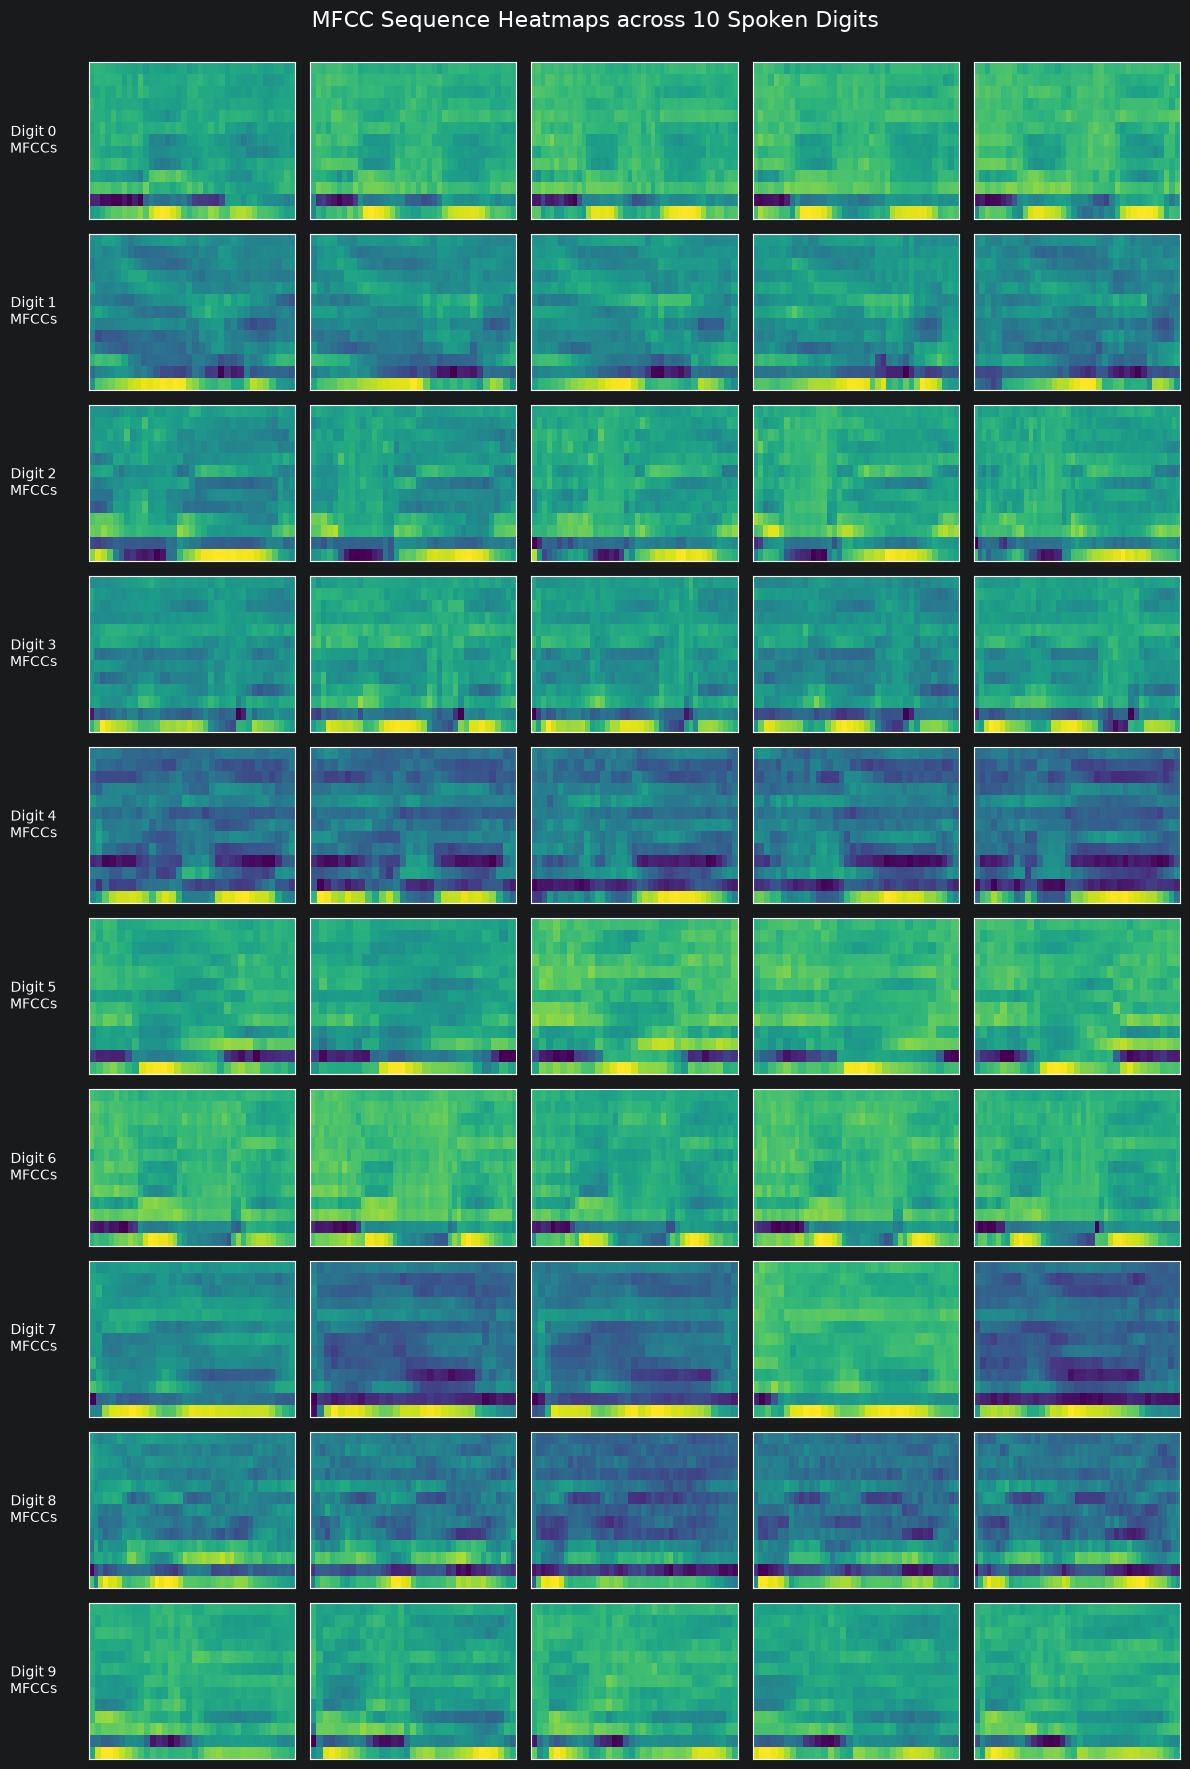

In [15]:
def plot_mfcc_heatmaps(dataset, samples_per_class=5, num_classes=10):
    fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(12, 18))
    counts = {i: 0 for i in range(num_classes)}

    for mfcc_seq, label in dataset:
        lbl = label.item()
        if counts[lbl] < samples_per_class:
            ax = axes[lbl, counts[lbl]]

            # Transpose so time is on x-axis and 13 MFCC coefficients are on y-axis[cite: 3]
            ax.imshow(mfcc_seq.numpy().T, cmap='viridis', aspect='auto', origin='lower')
            ax.set_xticks([])
            ax.set_yticks([])

            if counts[lbl] == 0:
                ax.set_ylabel(f"Digit {lbl}\nMFCCs", rotation=0, labelpad=40, va='center')

            counts[lbl] += 1

        if all(c == samples_per_class for c in counts.values()):
            break

    plt.suptitle("MFCC Sequence Heatmaps across 10 Spoken Digits", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

# Pass the raw dataset for unpadded visualization
plot_mfcc_heatmaps(train_dataset)